# Video lock: steadier answers on a live clip

In Milestone 3 the app shows a species when 4 of the last 6 frames agree on it, and how sure each
frame is never counts. On a real clip where Russell's viper sat near 62%, the shown answer changed
13 times. The new rule pools each frame's outputs over the last few frames with a snake (the window, 5 or 10, is tuned below):

- it pools every output the verdict rules read (species, WHO, genus and family probabilities and the
  embedding), shows "Checking..." until the pooled top species holds the confidence threshold and leads the
  runner-up by `margin`, then it **locks** on that species;
- a locked answer switches only when another species clearly leads for a full second;
- "dangerous" may show while checking; "not on the WHO list" and "we don't know" only after the lock.

This notebook runs both rules on the same clips. It tunes `window` and `margin` on dev clips only (synthetic clips
from validation photos plus real dev clips), then scores the test clips once
(while the method was being fixed this run's test clips were scored three times; section 6 says how).
The real clips are
Wikimedia Commons videos under CC BY, CC BY-SA, CC0 or public domain; the species comes from the file
page (`species_source` in `clips.csv`: `stated` in the text, `category` only in the file's category, or
`inferred` where the page names only the genus or "cobra"); species correctness is scored only on
`stated` and `category` clips. Their credits are in `clips.csv` and the clips folder. Set `MODEL_DIR` to rerun on
another model. No paid calls: everything runs on the laptop's CPU.

In [1]:
import hashlib, json, os, sys, urllib.request, warnings
from pathlib import Path

os.environ.update(YOLO_VERBOSE="False", YOLO_OFFLINE="1")
warnings.filterwarnings("ignore")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

sys.path.insert(0, "../src")
from serpentguard import decide, video
from serpentguard.data import AUGMENT, apply_mode, fix_exposure
from serpentguard.models import build_model

WORK = Path("../..")  # the folder beside the repo
MODEL_DIR = Path(os.environ.get("MODEL_DIR", WORK / "m3-video-demo/models"))  # best.pt, prototypes.npz, decision_metrics.json, detector.pt
CLIPS_DIR = Path(os.environ.get("CLIPS_DIR", WORK / "m4-video-clips"))  # real clips and CREDITS.md, never committed
METADATA = Path(os.environ.get("METADATA", WORK / "kaggle/clean_build/out/metadata.csv"))
RESULTS = Path("../results/m4/video")
MARGINS = (0.05, 0.1, 0.15, 0.2, 0.3)
WINDOWS = (5, 10)  # frames pooled; tuned with the margin
MAX_CHANGES, MAX_FIRST_ANSWER = 1, 3.0  # the tuning rule: median changes, median seconds to first answer
N_SYNTHETIC, SEED = 20, 42
N_LISTED_PER_SPECIES = 2  # synthetic clips per WHO-listed species with CC0 or CC BY validation photos
SYNTH_LICENCES = ("cc0", "cc-by")
MAX_CLIP_SECONDS = 30  # of a real clip
INFER_LATENCY = 0.1  # the phone reads at most 10 frames a second
CACHE = CLIPS_DIR / "cache"
RESULTS.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
print("model folder:", MODEL_DIR.name)

model folder: models


## 1. The model and the verdict rules

In [2]:
checkpoint = torch.load(MODEL_DIR / "best.pt", map_location="cpu", weights_only=True)
cfg = checkpoint["config"]
model = build_model(cfg, pretrained=False)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
decision = json.loads((MODEL_DIR / "decision_metrics.json").read_text())
thresholds = decide.Thresholds(**decision["thresholds"])
tau_snake = decision["no_snake"]["tau_snake"]
SCORER, SCALE = decision["scorer"], cfg.get("arcface_s")
with np.load(MODEL_DIR / "prototypes.npz") as saved:
    prototypes = saved[decision["prototype_set"]]
tables = decide.repo_tables()
classes = pd.read_csv("../data/classes.csv")
class_id = dict(zip(classes["species"], classes["class_id"]))
NAMES = classes.set_index("class_id")["species"]
detector = YOLO(MODEL_DIR / "detector.pt")
snake_class = [i for i, name in detector.names.items() if name.lower() == "snake"]
KEYS = ["embedding", "species_logits", "who_logits", "genus_logits", "family_logits"]
CONF = thresholds.theta_conf
MODEL_TAG = f"{cfg['run_id']}_{(MODEL_DIR / 'best.pt').stat().st_size}_v2"  # v2: heads and embedding cached
print(f"model {cfg['run_id']} ({SCORER} scorer); theta_conf {CONF:.3f}, theta_d {thresholds.theta_d:.3f}")

model H1_top1_s1 (head scorer); theta_conf 0.361, theta_d 0.057


## 2. One frame to its outputs

The same steps as the app (exposure fix, detector, crop, model); the frame's temperature-scaled species,
WHO, genus and family probabilities and its embedding come out, or `None` when the detector finds no
snake. The lock pools all of them, so the verdict rules see the same signals as for one photo.

In [3]:
def find_snake(rgb):
    found = detector.predict(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), conf=0.05, classes=snake_class,
                             rect=False, verbose=False)[0]
    if not len(found.boxes):
        return None, None
    best = int(found.boxes.conf.argmax())
    return found.boxes.xyxy[best].tolist(), float(found.boxes.conf[best])


def frame_outputs(frame):
    rgb = fix_exposure(frame)
    box, conf = find_snake(rgb)
    if conf is None or conf < tau_snake:
        return None
    crop = apply_mode(rgb, None, "box_crop", box, cfg["input_size"])[0]
    with torch.inference_mode():
        out = model(AUGMENT["eval"](image=crop)["image"][None])
    outputs = {key: out[key].float().numpy() for key in KEYS}
    found = decide.signals(outputs, thresholds.temperature, thresholds.temperature_who, prototypes,
                           tables, SCORER, SCALE)
    def row(head):
        return None if head is None else head[0]

    return {"probs": found.probs[0], "who": row(found.who_head), "genus": row(found.genus_head),
            "family": row(found.family_head), "embedding": outputs["embedding"][0]}


def read_video(path, max_side=640, max_fps=15, max_seconds=MAX_CLIP_SECONDS):
    capture = cv2.VideoCapture(str(path))
    source_fps = capture.get(cv2.CAP_PROP_FPS) or 15
    step = max(1, round(source_fps / max_fps))
    frames, n = [], 0
    while len(frames) < max_seconds * source_fps / step:
        ok, frame = capture.read()
        if not ok:
            break
        if n % step == 0:
            scale = min(1.0, max_side / max(frame.shape[:2]))
            if scale < 1:
                frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        n += 1
    capture.release()
    if not frames:
        raise ValueError(f"could not read any frames from {path}")
    return frames, source_fps / step


def clip_probs(name, make_frames):
    """(outputs per processed frame, None for no snake; when each result shows), cached per model."""
    cache = CACHE / f"{MODEL_TAG}__{name}.npz"
    if cache.exists():
        with np.load(cache) as saved:
            arrays, shown_at = {k: saved[k] for k in video.PART_NAMES if k in saved.files}, saved["shown_at"]
        return [None if np.isnan(arrays["probs"][i]).any()
                else {k: (arrays[k][i] if k in arrays else None) for k in video.PART_NAMES}
                for i in range(len(shown_at))], shown_at
    frames, fps = make_frames()
    kept, shown_at = video.schedule(len(frames), fps, INFER_LATENCY)
    items = [frame_outputs(frames[i]) for i in kept]
    first = next((item for item in items if item is not None), None)
    saved = {}
    for part in video.PART_NAMES:
        if first is None or first[part] is None:
            continue
        saved[part] = np.stack([np.full(first[part].shape, np.nan) if item is None else item[part]
                                for item in items])
    if "probs" not in saved:  # no snake on any frame
        saved["probs"] = np.full((len(items), len(classes)), np.nan)
    np.savez(cache, shown_at=shown_at, **saved)
    return items, shown_at

## 3. The two rules, scored per clip

For each clip: how many times the shown species changes after the first answer, how long until the
first answer, and whether the answer on screen at the end is right. The 4-of-6 vote votes on each
frame's top species; the lock is `video.pooled_lock`.

In [4]:
def shown_metrics(shown, times, true_class):
    answered = [(s, t) for s, t in zip(shown, times) if s is not None]
    changes = sum(a[0] != b[0] for a, b in zip(answered, answered[1:]))
    return {"changes": int(changes), "answered": bool(answered),
            "first_answer_s": round(float(answered[0][1]), 2) if answered else None,
            "final_shown": shown[-1] if shown else None,
            "final_right": bool(shown and shown[-1] is not None and shown[-1] == true_class)}


def vote_shown(probs):
    labels = [None if p is None else int(np.argmax(p["probs"])) for p in probs]
    snake = [i for i, label in enumerate(labels) if label is not None]
    voted = video.vote_k_of_n([labels[i] for i in snake])
    shown, last = [], None
    cursor = iter(voted)
    for i, label in enumerate(labels):
        if label is not None:
            last = next(cursor)
        shown.append(last)  # a frame with no snake leaves the screen as it was
    return shown


def lock_run(probs, times, margin, window):
    steps = video.pooled_lock(probs, times, CONF, margin, window=window)
    verdicts = video.lock_verdicts(steps, thresholds, prototypes, tables)
    return [s["species"] for s in steps], verdicts


def score_clip(probs, times, true_class, margin, window):
    species, verdicts = lock_run(probs, times, margin, window)
    expected = decide.expected_verdict(true_class, tables)
    return ({"vote": shown_metrics(vote_shown(probs), times, true_class),
             "lock": shown_metrics(species, times, true_class)},
            {"final_verdict": verdicts[-1], "expected_verdict": expected,
             "dangerous_missed": bool(tables.dangerous[true_class] and "dangerous" not in verdicts)},
            verdicts)


def photo_verdicts(probs):
    """The per-photo verdict of every processed frame, by the same code path the pool uses."""
    return [None if p is None else video.frame_verdict(video.frame_parts(p), thresholds, prototypes, tables)
            for p in probs]

## 4. The clips

**Real clips** are listed in `clips.csv` (clip, species, source url, licence, split) with the species
taken from each Commons file page; the split is by species, so no species is in both dev and test.
Two cobra clips name only the genus *Naja* or "a cobra" on their pages; we label them *Naja naja*
(the Indian cobra) as `inferred` (see `CREDITS.md`). They are scored for "dangerous" (any Naja is
dangerous) but **not** for species correctness, which uses only `stated` and `category` clips. The
split by species gives Naja to test (4 of the 7 species), because safety on a cobra has to be measured
on test; tuning uses dev only. Five of the ten real clips, and the eagle among the
negative clips, are CC BY-SA, outside the licences we meant to use (CC BY, CC0 and public domain).
They stay in the evaluation, since nothing is redistributed (the clips are kept outside the repo), and no
frame of a CC BY-SA clip goes into the report or the deck.
**Synthetic clips** (dev only) film validation photos licensed CC0 or CC BY with the project's clip
recipe; they come from the `url` column of the metadata: 20 of random species, and up to 2 photos of
every WHO-listed species that has such photos, to see whether "dangerous" shows.

In [5]:
manifest = pd.read_csv(RESULTS / "clips.csv")
assert set(manifest["split"]) <= {"dev", "test"}
assert not (set(manifest.loc[manifest.split == "dev", "species"])
            & set(manifest.loc[manifest.split == "test", "species"])), "a species is in both splits"
assert manifest["species"].isin(class_id).all() and manifest[["source_url", "licence"]].notna().all().all()
assert (CLIPS_DIR / manifest["clip"]).map(Path.exists).all()
assert set(manifest["species_source"]) <= {"stated", "category", "inferred"}
assert len(manifest) >= 10, "the brief asks for at least 10 real clips"
print(f"{len(manifest)} real clips, {manifest['species'].nunique()} species")
display(manifest.assign(clip=manifest["clip"].str[:40]).groupby(["split", "licence"]).size().rename("clips").reset_index())

10 real clips, 7 species


,split,licence,clips
0,dev,CC BY 3.0,2
1,dev,CC BY 4.0,1
2,dev,CC BY-SA 3.0,1
3,test,CC BY 2.0,1
4,test,CC BY-SA 2.0,1
5,test,CC BY-SA 4.0,3
6,test,Public domain,1


In [6]:
meta = pd.read_csv(METADATA, usecols=["species", "split", "license", "url", "attribution", "photo_id",
                                      "who_category"])
pool = meta[(meta.split == "val") & meta.license.isin(SYNTH_LICENCES) & meta.species.isin(class_id)]
random_pick = pool.groupby("species", group_keys=False).sample(1, random_state=SEED)
random_pick = random_pick.sample(N_SYNTHETIC, random_state=SEED).assign(group="random")
listed_pool = pool[pool.who_category.astype(str) != "not_listed"]
listed_pick = (listed_pool.sample(frac=1, random_state=SEED).groupby("species").head(N_LISTED_PER_SPECIES)
               .assign(group="who_listed"))
picked = pd.concat([random_pick, listed_pick[~listed_pick.photo_id.isin(random_pick.photo_id)]]).reset_index(drop=True)
PHOTOS = CLIPS_DIR / "val_photos"
PHOTOS.mkdir(exist_ok=True)
for row in picked.itertuples():
    target = PHOTOS / f"{row.photo_id}.jpg"
    if not target.exists():
        request = urllib.request.Request(row.url, headers={"User-Agent": "SerpentGuardStudentProject/1.0"})
        target.write_bytes(urllib.request.urlopen(request, timeout=60).read())
print(f"{len(picked)} synthetic clips from {picked.species.nunique()} species; "
      f"{picked.group.value_counts().to_dict()}; licences {picked.license.value_counts().to_dict()}")

46 synthetic clips from 31 species; {'who_listed': 26, 'random': 20}; licences {'cc-by': 44, 'cc0': 2}


In [7]:
def synthetic_frames(row):
    clip = video.synthesize_clip(video.load_raw_rgb(PHOTOS / f"{row.photo_id}.jpg"), seed=SEED + int(row.photo_id) % 10_000)
    return clip.frames, clip.params["fps"]


clips = []
for row in picked.itertuples():
    probs, times = clip_probs(f"synthetic_{row.photo_id}", lambda row=row: synthetic_frames(row))
    clips.append({"clip": f"synthetic_{row.photo_id}", "kind": f"synthetic_{row.group}", "species": row.species,
                  "split": "dev", "licence": row.license, "probs": probs, "times": times, "scored": True})
for row in manifest.itertuples():
    probs, times = clip_probs(row.clip, lambda row=row: read_video(CLIPS_DIR / row.clip))
    clips.append({"clip": row.clip, "kind": "real", "species": row.species, "split": row.split,
                  "licence": row.licence, "probs": probs, "times": times,
                  "scored": row.species_source != "inferred"})
for clip in clips:
    clip["true"] = class_id[clip["species"]]
    clip["snake_frames"] = sum(p is not None for p in clip["probs"])
    clip["who_listed"] = bool(tables.who[clip["true"]] != 0)
summary = pd.DataFrame([{k: c[k] for k in ("clip", "kind", "split", "species", "licence", "snake_frames")}
                        | {"frames": len(c["probs"])} for c in clips])
display(summary.groupby(["kind", "split"]).agg(clips=("clip", "size"), frames=("frames", "sum"),
                                               snake_frames=("snake_frames", "sum")))

clips  frames  snake_frames
kind                 split                             
real                 dev        4    1049          1037
                     test       6    1430          1149
synthetic_random     dev       20    2020          1889
synthetic_who_listed dev       26    2626          2438

## 5. Tuning `window` and `margin` on the dev clips

The window (5 or 10 frames pooled) and the margin are tuned together. The rule: among the pairs whose
**median** changes after the first answer is at most 1 and whose **median** time to the first answer
is at most 3 s (a clip that never answers counts as infinitely slow), take the smallest margin, and
the larger window on a tie. If no pair meets the rule we say so, and take the pair with the fewest
median changes, then the shortest median time to the first answer. A pair is only eligible if none of the clean negative clips (a
chameleon and an eagle, see section 8) ever locks under it: a shorter window answers faster but
locks on animals that are not snakes. The test clips are not touched here. The 10-frame window was a first guess, not a fixed requirement, which is why it is tuned.

In [8]:
DETECTOR_FALSE_ALARM = {"negative_river_wyoming.webm"}  # a river seen from the air; see section 8
negatives_manifest = pd.read_csv(RESULTS / "negatives.csv")
assert set(negatives_manifest["clip"]) == {p.name for p in CLIPS_DIR.glob("negative_*")}
negative_clips = {name: clip_probs(name, lambda name=name: read_video(CLIPS_DIR / name))
                  for name in negatives_manifest["clip"]}
clean_negatives = {n: v for n, v in negative_clips.items() if n not in DETECTOR_FALSE_ALARM}


def clean_negatives_locked(margin, window):
    return sum(any(s["state"] == "locked" for s in video.pooled_lock(probs, times, CONF, margin, window=window))
               for probs, times in clean_negatives.values())


dev = [c for c in clips if c["split"] == "dev"]
rows = []
for window in WINDOWS:
    for margin in MARGINS:
        scored = [score_clip(c["probs"], c["times"], c["true"], margin, window)[0]["lock"] for c in dev]
        rows.append({"window": window, "margin": margin,
                     "median_changes": float(np.median([s["changes"] for s in scored])),
                     "median_first_answer_s": float(np.median([s["first_answer_s"] if s["answered"] else np.inf
                                                               for s in scored])),
                     "never_answered": sum(not s["answered"] for s in scored),
                     "final_right": sum(s["final_right"] for s in scored),
                     "clean_negatives_locked": clean_negatives_locked(margin, window)})
tuning = pd.DataFrame(rows)
tuning["eligible"] = tuning.clean_negatives_locked == 0
assert tuning.eligible.any(), "every pair locks on a clean negative clip"
tuning["rule_met"] = (tuning.eligible & (tuning.median_changes <= MAX_CHANGES)
                      & (tuning.median_first_answer_s <= MAX_FIRST_ANSWER))
RULE_MET = bool(tuning.rule_met.any())
if RULE_MET:
    best = tuning[tuning.rule_met].sort_values(["margin", "window"], ascending=[True, False]).iloc[0]
else:
    best = tuning[tuning.eligible].sort_values(["median_changes", "median_first_answer_s", "margin", "window"],
                                               ascending=[True, True, True, False]).iloc[0]
MARGIN, WINDOW = float(best["margin"]), int(best["window"])
tuning["chosen"] = (tuning.window == WINDOW) & (tuning.margin == MARGIN)
ineligible = sorted({int(w) for w in tuning.loc[~tuning.eligible, "window"]})
tuning["note"] = ("pairs are eligible only if neither clean negative clip (chameleon, eagle) ever locks"
                  + (f"; window {ineligible} excluded because it locks on them" if ineligible else "")
                  + ("" if RULE_MET else "; rule not met on the M3 model: picked by fewest changes then shortest time to first answer; retune on the full model"))
tuning.to_csv(RESULTS / "margin_tuning.csv", index=False)
display(tuning.drop(columns="note"))
print(f"dev clips: {len(dev)}; "
      + ("rule met; " if RULE_MET else "RULE NOT MET ON THE M3 MODEL (picked by fewest changes, then shortest time to first answer; to be retuned on the full model); ")
      + f"chosen window {WINDOW}, margin {MARGIN}; video.POOL_FRAMES default is {video.POOL_FRAMES}")

,window,margin,median_changes,median_first_answer_s,never_answered,final_right,clean_negatives_locked,eligible,rule_met,chosen
0,5,0.05,0.0,3.15,15,14,2,False,False,False
1,5,0.10,0.0,3.15,15,14,2,False,False,False
2,5,0.15,0.0,3.15,15,14,2,False,False,False
3,5,0.20,0.0,3.15,15,14,2,False,False,False
4,5,0.30,0.0,4.10,17,12,2,False,False,False
5,10,0.05,0.0,6.20,22,10,0,True,False,True
6,10,0.10,0.0,6.20,22,10,0,True,False,False
7,10,0.15,0.0,6.20,22,10,0,True,False,False
8,10,0.20,0.0,6.50,22,11,0,True,False,False
9,10,0.30,0.0,9.10,24,10,0,True,False,False


dev clips: 50; RULE NOT MET ON THE M3 MODEL (picked by fewest changes, then shortest time to first answer; to be retuned on the full model); chosen window 10, margin 0.05; video.POOL_FRAMES default is 10


## 6. Both rules on every clip, dev and test

The vote is the M3 rule; the lock uses the chosen window and margin. The test clips are scored here,
once. They were not a single blind look: while the method was being fixed, they were scored three times (commits 88e7c56, 3c91907 and
da0a84a), `naja_naja_ditmars_1915.mp4` was a dev clip in the first of those and a test clip after, the
window tuning was added after the first test numbers, and the chameleon negative is cut from the same
1915 film. This copy is the last of the three runs.

In [9]:
records, danger_rows = [], []
for c in clips:
    both, verdict, lock_shown = score_clip(c["probs"], c["times"], c["true"], MARGIN, WINDOW)
    for method, m in both.items():
        records.append({"clip": c["clip"], "kind": c["kind"], "split": c["split"], "species": c["species"],
                        "licence": c["licence"], "method": method,
                        "window": WINDOW if method == "lock" else None,
                        "margin": MARGIN if method == "lock" else None,
                        "snake_frames": c["snake_frames"], "changes_after_first_answer": m["changes"],
                        "answered": m["answered"], "first_answer_s": m["first_answer_s"],
                        "final_shown": None if m["final_shown"] is None else NAMES[m["final_shown"]],
                        "final_right": m["final_right"] if c["scored"] else None,
                        **(verdict if method == "lock" else {})})
    # like for like: the frames with a snake; a "Checking" frame (None) is not "dangerous"
    snake_at = [i for i, p in enumerate(c["probs"]) if p is not None]
    photo_all = photo_verdicts(c["probs"])
    photo = [photo_all[i] == "dangerous" for i in snake_at]
    lock = [lock_shown[i] == "dangerous" for i in snake_at]
    danger_rows.append({"clip": c["clip"], "kind": c["kind"], "split": c["split"], "species": c["species"],
                        "who_listed": c["who_listed"], "dangerous_species": bool(tables.dangerous[c["true"]]),
                        "snake_frames": len(snake_at),
                        "photo_ever_dangerous": any(photo), "photo_last_dangerous": bool(photo) and photo[-1],
                        "photo_frame_share": float(np.mean(photo)) if photo else None,
                        "lock_ever_dangerous": any(lock), "lock_final_dangerous": bool(lock) and lock[-1],
                        "lock_frame_share": float(np.mean(lock)) if lock else None})
result = pd.DataFrame(records)
result.to_csv(RESULTS / "video_lock.csv", index=False)
danger = pd.DataFrame(danger_rows)
danger.to_csv(RESULTS / "danger_share.csv", index=False)
table = (result.groupby(["kind", "split", "method"])
         .agg(clips=("clip", "size"), species_scored=("final_right", "count"), median_changes=("changes_after_first_answer", "median"),
              mean_changes=("changes_after_first_answer", "mean"),
              median_first_answer_s=("first_answer_s", "median"), answered=("answered", "sum"),
              final_right=("final_right", "sum")).round(2))
display(table)

clips  species_scored  median_changes  \
kind                 split method                                          
real                 dev   lock        4               4             0.5   
                           vote        4               4            10.0   
                     test  lock        6               4             0.0   
                           vote        6               4             0.5   
synthetic_random     dev   lock       20              20             0.0   
                           vote       20              20             2.5   
synthetic_who_listed dev   lock       26              26             0.0   
                           vote       26              26             1.0   

                                   mean_changes  median_first_answer_s  \
kind                 split method                                        
real                 dev   lock            1.25                   1.70   
                           vote           10.25                   1.05   
                     test  lock            0.00                   1.00   
                           vote            2.00                   0.40   
synthetic_random     dev   lock            0.10                   1.00   
                           vote            2.55                   0.65   
synthetic_who_listed dev   lock            0.04                   1.45   
                           vote            1.69                   0.70   

                                   answered final_right  
kind                 split method                        
real                 dev   lock           3           1  
                           vote           4           3  
                     test  lock           5           1  
                           vote           6           1  
synthetic_random     dev   lock           9           2  
                           vote          20           3  
synthetic_who_listed dev   lock          16           7  
                           vote          25           6

In [10]:
test = result[result.split == "test"]
for method in ("vote", "lock"):
    part = test[test.method == method]
    print(f"test, {method}: {len(part)} clips, changes after first answer {part.changes_after_first_answer.tolist()}, "
          f"first answer {part.first_answer_s.round(2).tolist()}, final right {int(part.final_right.sum())}/{int(part.final_right.notna().sum())} "
          f"(species scored; {int(part.final_right.isna().sum())} clips left out as inferred)")
lock_test = test[test.method == "lock"]
print("lock verdict at the end vs expected:", list(zip(lock_test.final_verdict, lock_test.expected_verdict)))
print("clips whose lock never said dangerous though the species is:", int(lock_test.dangerous_missed.sum()))

test, vote: 6 clips, changes after first answer [0, 0, 1, 9, 2, 0], first answer [0.4, 0.4, 22.8, 0.8, 0.4, 0.4], final right 1/4 (species scored; 2 clips left out as inferred)
test, lock: 6 clips, changes after first answer [0, 0, 0, 0, 0, 0], first answer [1.0, 1.0, 25.0, nan, 1.0, 1.0], final right 1/4 (species scored; 2 clips left out as inferred)
lock verdict at the end vs expected: [('dangerous', 'dangerous'), ('not_listed', 'not_listed'), ('dangerous', 'not_listed'), ('dangerous', 'not_listed'), ('dangerous', 'dangerous'), ('dangerous', 'dangerous')]
clips whose lock never said dangerous though the species is: 0


**What the lock buys.** The gain is stability, not accuracy: the shown species changes far less
after the first answer, but the share of clips whose final answer is right is no better than the
4-of-6 vote's (see `final_right` above). When the model never gets sure of one species, the lock stays
on "Checking..." where the vote keeps changing its mind.

### "Dangerous" on dangerous species

For each clip of a WHO-listed species (real clips and the synthetic clips of listed species), does
"dangerous" show? Both paths are counted over the same frames, every frame with a snake; a "Checking" frame of the lock
counts as not showing "dangerous", and "at the end" is the screen on the last frame with a snake.
Per-photo is the verdict of each processed frame on its own (the photo path, with
all its signals); lock is the pooled verdict on the same frames. Shares are of clips.

In [11]:
def share(frame, column):
    return f"{int(frame[column].sum())}/{len(frame)}"


for name, part in (("real WHO-listed clips", danger[(danger.kind == "real") & danger.who_listed]),
                   ("synthetic WHO-listed clips", danger[(danger.kind == "synthetic_who_listed") & danger.who_listed]),
                   ("all dangerous-species clips", danger[danger.dangerous_species])):
    if len(part):
        print(f"{name}: n={len(part)}; dangerous shown at some point: photo {share(part, 'photo_ever_dangerous')}, "
              f"lock {share(part, 'lock_ever_dangerous')}; dangerous at the end: photo {share(part, 'photo_last_dangerous')}, "
              f"lock {share(part, 'lock_final_dangerous')}; share of frames: photo {part.photo_frame_share.mean():.2f}, "
              f"lock {part.lock_frame_share.mean():.2f}")
safe = danger[~danger.dangerous_species]
print(f"not-dangerous species (n={len(safe)}): dangerous shown at some point: photo {share(safe, 'photo_ever_dangerous')}, "
      f"lock {share(safe, 'lock_ever_dangerous')}; at the end: photo {share(safe, 'photo_last_dangerous')}, lock {share(safe, 'lock_final_dangerous')}")

real WHO-listed clips: n=4; dangerous shown at some point: photo 4/4, lock 4/4; dangerous at the end: photo 4/4, lock 4/4; share of frames: photo 0.90, lock 0.92
synthetic WHO-listed clips: n=26; dangerous shown at some point: photo 26/26, lock 26/26; dangerous at the end: photo 25/26, lock 26/26; share of frames: photo 0.95, lock 1.00
all dangerous-species clips: n=37; dangerous shown at some point: photo 37/37, lock 37/37; dangerous at the end: photo 36/37, lock 37/37; share of frames: photo 0.95, lock 0.99
not-dangerous species (n=19): dangerous shown at some point: photo 18/19, lock 17/19; at the end: photo 14/19, lock 15/19


## 7. What the screen shows over time

Real CC clips only (credits in `clips.csv`). Each row is a clip; grey dots are the top species of
each processed frame, the blue line is the 4-of-6 vote, the red line is the lock.

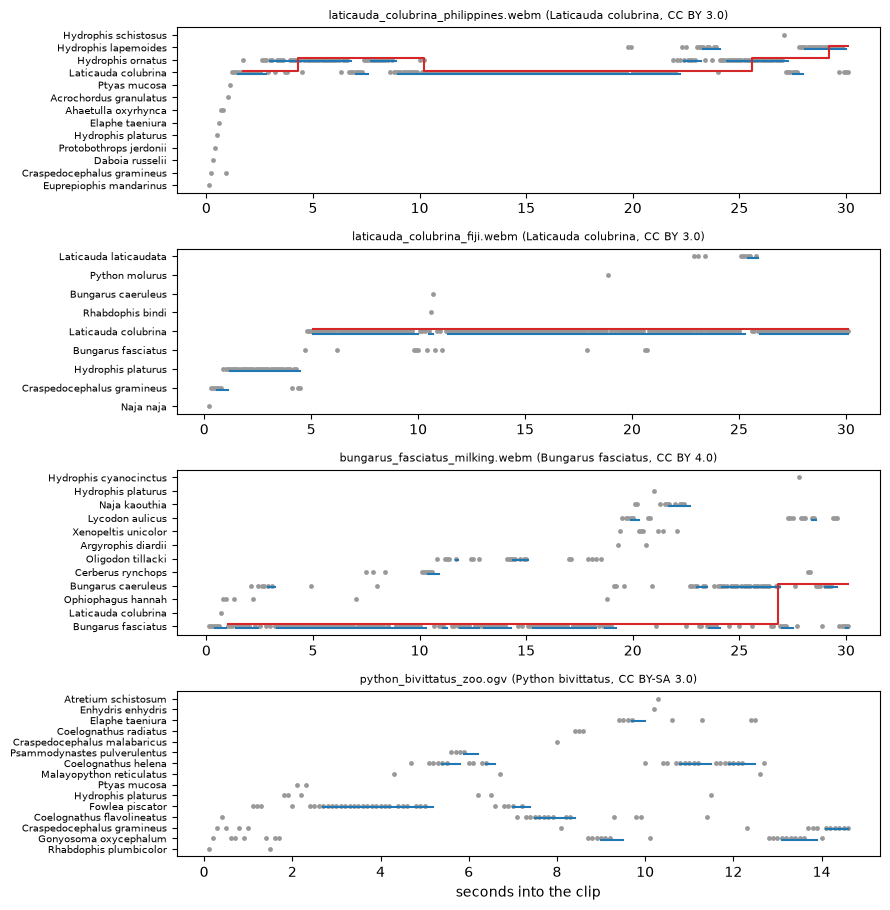

In [12]:
def show_timeline(c, ax):
    probs, times = c["probs"], c["times"]
    locked, _ = lock_run(probs, times, MARGIN, WINDOW)
    voted = vote_shown(probs)
    tops = [None if p is None else int(np.argmax(p["probs"])) for p in probs]
    seen = [s for s in dict.fromkeys(tops + voted + locked) if s is not None]
    row = {s: i for i, s in enumerate(seen)}

    def height(series, offset):
        return [np.nan if s is None else row[s] + offset for s in series]

    ax.scatter(times, height(tops, 0), color="0.6", s=6)
    ax.step(times, height(voted, -0.12), where="post", color="tab:blue", lw=1.5)
    ax.step(times, height(locked, 0.12), where="post", color="tab:red", lw=1.5)
    ax.set_yticks(range(len(seen)), [NAMES[s] for s in seen], fontsize=7)
    ax.set_title(f"{c['clip'][:48]} ({c['species']}, {c['licence']})", fontsize=8)


real = [c for c in clips if c["kind"] == "real"][:4]
fig, axes = plt.subplots(len(real), 1, figsize=(9, 2.3 * len(real)), squeeze=False)
for c, ax in zip(real, axes[:, 0]):
    show_timeline(c, ax)
axes[-1, 0].set_xlabel("seconds into the clip")
plt.tight_layout()
plt.show()

## 8. Checks

Every real clip has its licence and source url recorded; a clip with no snake must never lock; and
no result holds a missing value where one is needed.

The negative controls (`negatives.csv`) are CC clips of other things: a chameleon, an eagle and a
river seen from a drone. The lock needs a detector box on a full window of frames and then a
confident pooled species. With the chosen window the chameleon and the eagle never lock (a window of 5
did lock on them, which is why a pair must keep them unlocked to be eligible). The river is a **detector
false alarm**: the M3 detector calls the winding river a snake on about half the frames and the model
is then confident about it. That is the detector's error, upstream of the lock, and fixing it is the
job of notebook 20's no-snake gate; the rerun on the full model will use that gate. The river stays in the
record, listed and not asserted.

In [13]:
assert manifest[["clip", "species", "source_url", "licence", "split"]].notna().all().all()
assert set(manifest["licence"]) <= {"CC BY 2.0", "CC BY 3.0", "CC BY 4.0", "CC BY-SA 2.0", "CC BY-SA 3.0",
                                    "CC BY-SA 4.0", "CC0", "Public domain"}
assert negatives_manifest[["clip", "source_url", "licence"]].notna().all().all()
rows = []
for name, (probs, times) in negative_clips.items():
    steps = video.pooled_lock(probs, times, CONF, MARGIN, window=WINDOW)
    verdicts = video.lock_verdicts(steps, thresholds, prototypes, tables)
    rows.append({"clip": name, "frames": len(probs), "snake_frames": sum(p is not None for p in probs),
                 "locked_frames": sum(s["state"] == "locked" for s in steps),
                 "verdicts_shown": sorted({v for v in verdicts if v})})
negatives = pd.DataFrame(rows)
display(negatives)
clean = negatives[~negatives["clip"].isin(DETECTOR_FALSE_ALARM)]
assert len(clean) >= 2 and (clean.locked_frames == 0).all(), "a clip with no snake locked"
# with no snake found at all the lock is never reached, whatever the clip length
assert all(s["state"] == "checking" for s in video.pooled_lock([None] * 40, np.arange(40) / 10, CONF, MARGIN))
missing = result.drop(columns=["window", "margin", "first_answer_s", "final_shown", "final_verdict",
                               "expected_verdict", "dangerous_missed", "final_right"]).isna().sum().sum()
unanswered_without_flag = int((result.first_answer_s.isna() & result.answered).sum())
print("empty cells in the counted columns:", int(missing), "; answered clips without a time:", unanswered_without_flag)
assert missing == 0 and unanswered_without_flag == 0
print("negative controls run:", len(negatives))

,clip,frames,snake_frames,locked_frames,verdicts_shown
0,negative_chameleon_1915.mp4,301,301,0,[dangerous]
1,negative_eagle_goa.ogv,189,184,0,[dangerous]
2,negative_river_wyoming.webm,301,151,234,[dangerous]


empty cells in the counted columns: 0 ; answered clips without a time: 0
negative controls run: 3
